In [18]:
%load_ext autoreload
%autoreload 2

In [19]:
import pandas as pd
import numpy as np
import io
import re
import networkx as nx
from math import prod

from io import StringIO
from itertools import product, combinations, permutations
from scipy.stats import pearsonr

from matplotlib import pyplot as plt
from matplotlib import rcParams
import seaborn as sns

import logging

In [20]:
from utils.countryconverter import convert_country_df
from utils.utils import load_csv_files_from_folder
from analysis.regression import compute_deltas

In [21]:
logger = logging.getLogger()
#logger.setLevel(logging.DEBUG)
logger.setLevel(logging.INFO)

In [22]:
POWER_DATA_DIR = "../data/raw/power/"
BASIC_PROCESSED_POWER_DATA_DIR = "../data/basic_preprocessed/power/"

PREDICTORS_DATA_DIR = "../data/raw/predictors/"
BASIC_PROCESSED_PREDICTORS_DATA_DIR = "../data/basic_preprocessed/predictors/"

#### functions

# Data load

In [23]:
from utils.input import read_subsystems

In [24]:
subsystems=read_subsystems()

INFO:root:Сканируем папку: /home/alex-server/Sync/Работа/Code/phd_thesis/data/preprocessed/subsystem_level
INFO:root:Содержимое папки (4 элементов):
INFO:root:  - df_economy_2022.csv
INFO:root:  - df_security_2022.csv
INFO:root:  - df_human_2022.csv
INFO:root:  - .ipynb_checkpoints
INFO:root:Добавлена категория: 'economy' из файла df_economy_2022.csv
INFO:root:Добавлена категория: 'security' из файла df_security_2022.csv
INFO:root:Добавлена категория: 'human' из файла df_human_2022.csv
INFO:root:Найдено уникальных категорий: 3
INFO:root:Итоговый список категорий: ['economy', 'human', 'security']
INFO:root:reading subsystems ['economy', 'human', 'security']


In [25]:
analysis=pd.read_csv('../data/analysis.csv', index_col='Unnamed: 0')
status_combined=pd.read_csv('../data/status_combined.csv')

In [26]:
subsystems

{'economy': {'networks': {1992: <networkx.classes.digraph.DiGraph at 0x7f52fadcee50>,
   1993: <networkx.classes.digraph.DiGraph at 0x7f52fad6c970>,
   1994: <networkx.classes.digraph.DiGraph at 0x7f52fad6cf70>,
   1995: <networkx.classes.digraph.DiGraph at 0x7f52fad6c790>,
   1996: <networkx.classes.digraph.DiGraph at 0x7f52fad6c940>,
   1997: <networkx.classes.digraph.DiGraph at 0x7f52fad6cd60>,
   1998: <networkx.classes.digraph.DiGraph at 0x7f52fad6c8e0>,
   1999: <networkx.classes.digraph.DiGraph at 0x7f52fad6c8b0>,
   2000: <networkx.classes.digraph.DiGraph at 0x7f52f9947a00>,
   2001: <networkx.classes.digraph.DiGraph at 0x7f52f9947430>,
   2002: <networkx.classes.digraph.DiGraph at 0x7f52f99479d0>,
   2003: <networkx.classes.digraph.DiGraph at 0x7f52f9947910>,
   2004: <networkx.classes.digraph.DiGraph at 0x7f52faca3880>,
   2005: <networkx.classes.digraph.DiGraph at 0x7f52faca3580>,
   2006: <networkx.classes.digraph.DiGraph at 0x7f52faca3a30>,
   2007: <networkx.classes.digra

In [27]:
status_combined

,ego,year,centrality,rank,status,subsystem,weighted_centrality,rank_combined
0,Австралия,1985,0.079260,33.0,63.112745,securityeconomyhuman,0.069804,5.0
1,Австралия,1986,0.079208,33.0,63.196078,securityeconomyhuman,0.069416,6.0
2,Австралия,1987,0.079552,33.0,63.112745,securityeconomyhuman,0.069978,6.0
3,Австралия,1988,0.079501,33.0,63.112745,securityeconomyhuman,0.069496,6.0
4,Австралия,1989,0.079098,34.0,63.321770,securityeconomyhuman,0.068515,7.0
...,...,...,...,...,...,...,...,...
7174,Япония,2018,0.040151,76.0,34.489697,securityeconomyhuman,0.029155,15.0
7175,Япония,2019,0.037707,74.0,33.931576,securityeconomyhuman,0.027315,16.0
7176,Япония,2020,0.037934,76.0,33.761364,securityeconomyhuman,0.028184,16.0
7177,Япония,2021,0.037068,77.0,33.681364,securityeconomyhuman,0.027734,18.0


In [59]:
df_sorted = status_combined.sort_values(['ego', 'year'])
df_sorted['delta']=df_sorted.groupby(['ego'])['weighted_centrality'].diff()
df_sorted=df_sorted.dropna(subset='delta')

df_sorted = df_sorted[['ego','year','delta']]
df_sorted = df_sorted.merge(abs(df_sorted.groupby(['ego'])['delta'].mean()), on='ego', suffixes=('','mean'))
df_sorted=df_sorted[df_sorted['deltamean']>0.0001]

## Корреляционный анализ

In [60]:
import pandas as pd
import numpy as np
from itertools import combinations

# ----------------------
# Ваш DataFrame: df с колонками country, year, delta
# ----------------------

# 1. Сводная таблица: строки – годы, столбцы – страны
pivot = df_sorted.pivot(index='year', columns='ego', values='delta')

# 2. Матрица корреляций Спирмена
corr_matrix = pivot.corr(method='spearman')

# 3. Извлекаем все уникальные пары стран и их корреляции (верхний треугольник)
pairs = []
countries = corr_matrix.columns
for i, c1 in enumerate(countries):
    for c2 in countries[i+1:]:
        corr_val = corr_matrix.loc[c1, c2]
        if not pd.isna(corr_val):          # отбрасываем NaN
            pairs.append((c1, c2, corr_val))

# 4. Сортируем пары по убыванию корреляции (от самых больших к меньшим)
pairs_sorted = sorted(pairs, key=lambda x: x[2], reverse=True)

# 5. Задаём, сколько топ-пар вывести
top_n = 50   # можно поменять на любое число

print(f"Топ-{top_n} наибольших корреляций Спирмена между странами:")
for c1, c2, corr in pairs_sorted[:top_n]:
    print(f"  {c1} – {c2}: {corr:.4f}")


print(f"Топ-{top_n} наименьших корреляций Спирмена между странами:")
for c1, c2, corr in pairs_sorted[-top_n:]:
    print(f"  {c1} – {c2}: {corr:.4f}")

# (Опционально) Если нужны и самые маленькие (отрицательные) – раскомментируйте:
# print(f"\nТоп-{top_n} наименьших корреляций:")
# for c1, c2, corr in pairs_sorted[-top_n:]:
#     print(f"  {c1} – {c2}: {corr:.4f}")

Топ-50 наибольших корреляций Спирмена между странами:
  Словакия – Чехия: 0.7319
  Бельгия – Черногория: 0.6863
  Люксембург – Словакия: 0.6613
  Черногория – Чехословакия: 0.6569
  Люксембург – Чехия: 0.6169
  Бразилия – Чехия: 0.6089
  Аргентина – Черногория: 0.6029
  Индонезия – Словакия: 0.6008
  Индонезия – Чехия: 0.5979
  Бразилия – Польша: 0.5894
  Индонезия – Черногория: 0.5882
  Бельгия – Германия: 0.5813
  Болгария – Черногория: 0.5809
  Алжир – Саудовская Аравия: 0.5780
  Индия – Чехия: 0.5744
  Бельгия – Франция: 0.5721
  Венгрия – Люксембург: 0.5562
  Польша – Словакия: 0.5423
  Иордания – Китай: 0.5287
  Таиланд – Чехословакия: 0.5268
  Венгрия – Венесуэла: 0.5263
  Индия – Словакия: 0.5262
  Словакия – Таиланд: 0.5242
  Германия – Франция: 0.5220
  Мексика – США: 0.5218
  Бразилия – Словакия: 0.5125
  Иордания – Чехия: 0.5103
  Индонезия – Люксембург: 0.5092
  Бразилия – Индонезия: 0.5005
  Венгрия – Словакия: 0.4964
  Иордания – Нидерланды: 0.4962
  Аргентина – Индонези

In [63]:
correls = pd.DataFrame(pairs_sorted, columns=['country_a','country_b','perason_r'])
correls.to_csv('../output/further/pearson_basic.csv')
correls

,country_a,country_b,perason_r
0,Словакия,Чехия,0.731855
1,Бельгия,Черногория,0.686275
2,Люксембург,Словакия,0.661290
3,Черногория,Чехословакия,0.656863
4,Люксембург,Чехия,0.616935
...,...,...,...
1030,Норвегия,Сингапур,-0.495021
1031,Италия,Люксембург,-0.495733
1032,Венесуэла,Румыния,-0.500237
1033,Ирландия,Россия,-0.514462


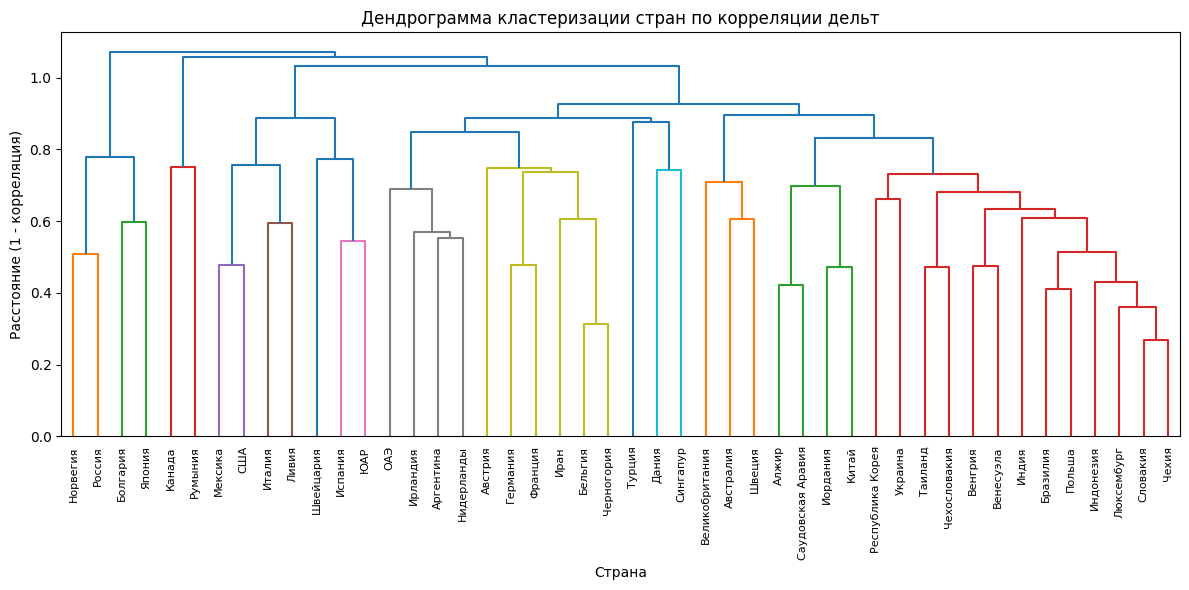

Оптимальное число кластеров по силуэту: 2

Кластеры стран (на основе взаимной корреляции дельт):
Кластер 1: ['Болгария', 'Норвегия', 'Россия', 'Япония']
Кластер 2: ['Австралия', 'Австрия', 'Алжир', 'Аргентина', 'Бельгия', 'Бразилия', 'Великобритания', 'Венгрия', 'Венесуэла', 'Германия', 'Дания', 'Индия', 'Индонезия', 'Иордания', 'Иран', 'Ирландия', 'Испания', 'Италия', 'Канада', 'Китай', 'Ливия', 'Люксембург', 'Мексика', 'Нидерланды', 'ОАЭ', 'Польша', 'Республика Корея', 'Румыния', 'США', 'Саудовская Аравия', 'Сингапур', 'Словакия', 'Таиланд', 'Турция', 'Украина', 'Франция', 'Черногория', 'Чехия', 'Чехословакия', 'Швейцария', 'Швеция', 'ЮАР']


In [134]:
import pandas as pd
import numpy as np
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# ---------- Подготовка данных ----------
# df должен содержать колонки: country, year, delta
pivot = df_sorted.pivot(index='year', columns='ego', values='delta')
corr_matrix = pivot.corr(method='spearman')   # матрица корреляций Спирмена

# Преобразуем корреляции в расстояние: d = 1 - corr (диапазон [0,2])
# Для кластеризации используем метрику, основанную на этом расстоянии.
distance_matrix = 1 - corr_matrix
# Приводим к компактному виду (condensed) для функции linkage
dist_condensed = squareform(distance_matrix, checks=False)

# ---------- Кластеризация ----------
# Метод связи: 'average' (UPGMA) хорошо работает с корреляционными расстояниями
linkage_matrix = linkage(dist_condensed, method='average')

# Опционально: построим дендрограмму, чтобы визуально оценить структуру
plt.figure(figsize=(12, 6))
dendrogram(linkage_matrix, labels=corr_matrix.index, leaf_rotation=90)
plt.title('Дендрограмма кластеризации стран по корреляции дельт')
plt.xlabel('Страна')
plt.ylabel('Расстояние (1 - корреляция)')
plt.tight_layout()
plt.show()

# ---------- Выбор числа кластеров по силуэту ----------
sil_scores = []
max_clusters = min(10, len(corr_matrix.index))
for n_clust in range(2, max_clusters + 1):
    labels = fcluster(linkage_matrix, n_clust, criterion='maxclust')
    if len(set(labels)) > 1:
        sil = silhouette_score(distance_matrix, labels, metric='precomputed')
        sil_scores.append((n_clust, sil))
    else:
        sil_scores.append((n_clust, -1))

best_n = max(sil_scores, key=lambda x: x[1])[0]
print(f"Оптимальное число кластеров по силуэту: {best_n}")

# ---------- Получение итоговых кластеров ----------
cluster_labels = fcluster(linkage_matrix, best_n, criterion='maxclust')
clusters = {}
for country, lbl in zip(corr_matrix.index, cluster_labels):
    clusters.setdefault(lbl, []).append(country)

print("\nКластеры стран (на основе взаимной корреляции дельт):")
for lbl, countries in sorted(clusters.items()):
    print(f"Кластер {lbl}: {countries}")

In [72]:
corr_matrix

ego,Австралия,Австрия,Азербайджан,Албания,Алжир,Ангола,Андорра,Антигуа и Барбуда,Аргентина,Армения,...,Эквадор,Экваториальная Гвинея,Эритрея,Эсватини,Эстония,Эфиопия,ЮАР,Южный Судан,Ямайка,Япония
ego,,,,,,,,,,,,,,,,,,,,,
Австралия,1.000000,0.139237,0.047649,0.088968,-0.130702,0.023677,0.170416,0.165870,0.271519,0.202353,...,0.491021,0.147837,0.991116,0.107277,0.479995,0.047792,-0.054909,NaN,-0.021009,-0.231805
Австрия,0.139237,1.000000,-0.029196,-0.117574,-0.053175,0.293453,-0.008066,-0.008942,0.175102,0.696712,...,-0.000783,0.066738,0.947452,-0.139032,0.313055,-0.226276,0.082018,NaN,-0.525107,0.109154
Азербайджан,0.047649,-0.029196,1.000000,-0.442972,0.379782,-0.228147,0.728137,-1.000000,0.026951,0.935088,...,-0.168828,-0.504339,0.908130,0.618655,-0.187612,0.451108,-0.334160,NaN,-0.032229,0.358880
Албания,0.088968,-0.117574,-0.442972,1.000000,0.992812,-0.816522,0.962318,0.987144,0.559505,1.000000,...,0.795771,0.962169,1.000000,NaN,1.000000,0.942700,0.651280,NaN,0.984769,-0.749564
Алжир,-0.130702,-0.053175,0.379782,0.992812,1.000000,0.049708,0.892435,0.936693,-0.102570,0.405129,...,0.583152,0.927937,-1.000000,-0.572165,-0.520214,0.459601,0.180843,NaN,0.981784,-0.106785
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Эфиопия,0.047792,-0.226276,0.451108,0.942700,0.459601,-0.467346,0.702093,0.877296,0.205362,0.308952,...,0.716894,0.558185,1.000000,-0.485779,0.947026,1.000000,0.212998,NaN,0.617714,-0.468153
ЮАР,-0.054909,0.082018,-0.334160,0.651280,0.180843,0.156478,0.226279,0.627415,-0.152918,-0.416349,...,-0.089835,-0.116044,-0.450845,0.217558,0.338665,0.212998,1.000000,NaN,-0.132182,0.010691
Южный Судан,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [99]:
abs(df_sorted.groupby(['ego'])['delta'].mean())

ego
Австралия      0.000362
Австрия        0.000309
Азербайджан    0.000042
Албания        0.000012
Алжир          0.000152
                 ...   
Эфиопия        0.000051
ЮАР            0.000206
Южный Судан    0.000005
Ямайка         0.000033
Япония         0.000549
Name: delta, Length: 196, dtype: float64

In [112]:
# ОТКУДА У МЕНЯ ГДР ПОСЛЕ 1999?

## Network coevolution

In [138]:
Gs=subsystems['security']['networks']

In [145]:
import networkx as nx
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import roc_auc_score, average_precision_score, mean_squared_error, r2_score

# ------------------------------------------------------------------
# 1. ПРИЗНАКИ ДЛЯ ПАРЫ (u, v)
# ------------------------------------------------------------------

def directed_neighborhood_features(G, u, v):
    """
    Признаки из последнего доступного графа G.
    Для направленного ребра u -> v:
      common neighbors = successors(u) ∩ predecessors(v)
    """
    out_u = set(G.successors(u)) if G.has_node(u) else set()
    in_v  = set(G.predecessors(v)) if G.has_node(v) else set()

    common = out_u & in_v
    union  = out_u | in_v

    cn = len(common)
    jc = cn / len(union) if union else 0.0

    aa = 0.0
    ra = 0.0
    for w in common:
        d = G.out_degree(w) + G.in_degree(w)
        if d > 1:
            aa += 1.0 / np.log(d)
        if d > 0:
            ra += 1.0 / d

    pa = len(out_u) * len(in_v)

    # взвешенные характеристики (используется только weight)
    common_weight_sum = 0.0
    for w in common:
        if G.has_edge(u, w):
            common_weight_sum += G[u][w].get('weight', 1.0)
        if G.has_edge(w, v):
            common_weight_sum += G[w][v].get('weight', 1.0)

    weighted_out = sum(G[u][x].get('weight', 1.0) for x in out_u if G.has_edge(u, x))
    weighted_in  = sum(G[x][v].get('weight', 1.0) for x in in_v if G.has_edge(x, v))

    return {
        'common_neighbors': cn,
        'jaccard': jc,
        'adamic_adar': aa,
        'resource_allocation': ra,
        'preferential_attachment': pa,
        'common_weight_sum': common_weight_sum,
        'weighted_out_strength': weighted_out,
        'weighted_in_strength': weighted_in,
    }


def temporal_edge_features(history, u, v, window=5):
    """
    Признаки динамики ребра u -> v по истории графов.
    history: список nx.DiGraph, отсортированный по годам.
    """
    weights = []
    for G in history:
        if G.has_edge(u, v):
            weights.append(G[u][v].get('weight', 1.0))
        else:
            weights.append(0.0)

    total_years_with_edge = sum(1 for x in weights if x != 0)

    recent = weights[-window:] if len(weights) >= window else weights
    recent_count = sum(1 for x in recent if x != 0)

    mean_weight_nonzero = (
        np.mean([x for x in weights if x != 0]) if total_years_with_edge > 0 else 0.0
    )
    recent_mean = np.mean(recent) if recent else 0.0

    slope = 0.0
    if len(recent) >= 2:
        slope = float(np.polyfit(np.arange(len(recent)), recent, 1)[0])

    return {
        'past_edge_count': total_years_with_edge,
        'recent_edge_count': recent_count,
        'past_mean_weight': mean_weight_nonzero,
        'recent_mean_weight': recent_mean,
        'weight_trend': slope,
    }


def build_pair_features(history, u, v, window=5):
    """
    Итоговый вектор признаков для ребра u -> v.
    history — все предыдущие графы до целевого года включительно.
    """
    G_latest = history[-1] if history else nx.DiGraph()

    feats = {}
    feats.update(directed_neighborhood_features(G_latest, u, v))
    feats.update(temporal_edge_features(history, u, v, window))

    feats['u_out_degree'] = G_latest.out_degree(u) if G_latest.has_node(u) else 0
    feats['v_in_degree'] = G_latest.in_degree(v) if G_latest.has_node(v) else 0
    feats['u_in_degree'] = G_latest.in_degree(u) if G_latest.has_node(u) else 0
    feats['v_out_degree'] = G_latest.out_degree(v) if G_latest.has_node(v) else 0

    return feats


# ------------------------------------------------------------------
# 2. ФОРМИРОВАНИЕ ОБУЧАЮЩЕЙ ВЫБОРКИ
# ------------------------------------------------------------------

def sample_negative_edges(target_graph, nodes, n_neg, seed=0):
    rng = np.random.default_rng(seed)
    existing = set(target_graph.edges())
    nodes_arr = np.array(nodes)

    neg = set()
    attempts = 0
    max_attempts = n_neg * 20 + 100

    while len(neg) < n_neg and attempts < max_attempts:
        u = nodes_arr[rng.integers(0, len(nodes_arr))]
        v = nodes_arr[rng.integers(0, len(nodes_arr))]
        if u != v and (u, v) not in existing and (u, v) not in neg:
            neg.add((u, v))
        attempts += 1

    return list(neg)


def create_link_dataset(history, target_graph, neg_ratio=1.0, seed=0):
    """
    history: список графов до года t
    target_graph: граф года t+1
    Возвращает DataFrame с признаками и меткой label (1 — есть ребро, 0 — нет).
    """
    nodes = set()
    for G in history:
        nodes.update(G.nodes())
    nodes.update(target_graph.nodes())
    nodes = list(nodes)

    pos_edges = list(target_graph.edges())
    n_neg = max(int(len(pos_edges) * neg_ratio), 1)
    neg_edges = sample_negative_edges(target_graph, nodes, n_neg, seed)

    rows = []
    for u, v in pos_edges:
        feats = build_pair_features(history, u, v)
        rows.append({**feats, 'label': 1})

    for u, v in neg_edges:
        feats = build_pair_features(history, u, v)
        rows.append({**feats, 'label': 0})

    return pd.DataFrame(rows)


def create_weight_dataset(history, target_graph):
    """
    Только для существующих рёбер целевого года.
    Целевая переменная — weight.
    """
    rows = []
    for u, v, data in target_graph.edges(data=True):
        w = data.get('weight', 1.0)
        feats = build_pair_features(history, u, v)
        rows.append({**feats, 'weight': w})
    return pd.DataFrame(rows)


def build_train_link_df(Gs, train_years):
    """
    Gs: словарь {год: nx.DiGraph}
    train_years: список лет для обучения, например 1992..2020
    Создаёт обучающую выборку по всем переходам внутри train_years.
    """
    frames = []
    sorted_years = sorted(train_years)

    for i in range(len(sorted_years) - 1):
        t = sorted_years[i]
        t_next = sorted_years[i + 1]

        history_years = sorted_years[:i + 1]
        history = [Gs[y] for y in history_years]
        target = Gs[t_next]

        df = create_link_dataset(history, target, neg_ratio=1.0, seed=t_next)
        frames.append(df)

    return pd.concat(frames, ignore_index=True)


def build_train_weight_df(Gs, train_years):
    frames = []
    sorted_years = sorted(train_years)

    for i in range(len(sorted_years) - 1):
        t = sorted_years[i]
        t_next = sorted_years[i + 1]

        history_years = sorted_years[:i + 1]
        history = [Gs[y] for y in history_years]
        target = Gs[t_next]

        df = create_weight_dataset(history, target)
        frames.append(df)

    return pd.concat(frames, ignore_index=True)


# ------------------------------------------------------------------
# 3. ОБУЧЕНИЕ И ОЦЕНКА
# ------------------------------------------------------------------

# Используем ваш словарь Gs (годы 1992..2022)
# Предполагается, что Gs уже заполнен и содержит DiGraph с рёбрами и атрибутом 'weight'
all_years = sorted(Gs.keys())
train_years = [y for y in all_years if y <= 2020]   # обучение до 2020 включительно
test_years = [y for y in all_years if y > 2020]     # тестовые: 2021, 2022

print(f"Обучение на годах: {train_years[0]}–{train_years[-1]}")
print(f"Тестирование на годах: {test_years}")

# --- Признаки для модели предсказания наличия ребра ---
train_link_df = build_train_link_df(Gs, train_years)

feature_cols = [c for c in train_link_df.columns if c != 'label']
X_train = train_link_df[feature_cols]
y_train = train_link_df['label']

link_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
link_model.fit(X_train, y_train)


def evaluate_link_model(model, Gs, history_years, test_year, neg_ratio=1.0):
    history = [Gs[y] for y in history_years]
    target = Gs[test_year]

    df = create_link_dataset(history, target, neg_ratio=neg_ratio, seed=test_year)
    X = df[feature_cols]
    y = df['label']

    proba = model.predict_proba(X)[:, 1]

    auc = roc_auc_score(y, proba)
    ap = average_precision_score(y, proba)

    print(f"Тест {test_year}: ROC-AUC = {auc:.4f}, Average Precision = {ap:.4f}")
    return auc, ap, df


# --- Модель предсказания веса ребра ---
train_weight_df = build_train_weight_df(Gs, train_years)
Xw_train = train_weight_df[feature_cols]
yw_train = train_weight_df['weight']

weight_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)
weight_model.fit(Xw_train, yw_train)


def evaluate_weight_model(model, Gs, history_years, test_year):
    history = [Gs[y] for y in history_years]
    target = Gs[test_year]

    df = create_weight_dataset(history, target)
    X = df[feature_cols]
    y_true = df['weight']

    y_pred = model.predict(X)

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print(f"Веса {test_year}: RMSE = {rmse:.4f}, R2 = {r2:.4f}")
    return rmse, r2, df


# ------------------------------------------------------------------
# 4. ТЕСТИРОВАНИЕ НА 2021 И 2022
# ------------------------------------------------------------------

print("\n=== Link prediction ===")

# Для 2021: история все годы до 2021 (1992..2020)
auc_21, ap_21, df_21 = evaluate_link_model(
    link_model,
    Gs,
    history_years=[y for y in all_years if y < 2021],
    test_year=2021
)

# Для 2022: история все годы до 2022 (1992..2021)
# 2021 здесь используется только как входной граф, но не для обучения модели
auc_22, ap_22, df_22 = evaluate_link_model(
    link_model,
    Gs,
    history_years=[y for y in all_years if y < 2022],
    test_year=2022
)

print("\n=== Weight prediction ===")

rmse_21, r2_21, wdf_21 = evaluate_weight_model(
    weight_model,
    Gs,
    history_years=[y for y in all_years if y < 2021],
    test_year=2021
)

rmse_22, r2_22, wdf_22 = evaluate_weight_model(
    weight_model,
    Gs,
    history_years=[y for y in all_years if y < 2022],
    test_year=2022
)

Обучение на годах: 1992–2020
Тестирование на годах: [2021, 2022]

=== Link prediction ===
Тест 2021: ROC-AUC = 0.9894, Average Precision = 0.9915
Тест 2022: ROC-AUC = 0.9936, Average Precision = 0.9943

=== Weight prediction ===
Веса 2010: RMSE = 23.9565, R2 = 0.4376
Веса 2022: RMSE = 17.0242, R2 = 0.8191


In [149]:
subsystems['economy']['networks']

{1992: <networkx.classes.digraph.DiGraph at 0x7fb86b597f70>,
 1993: <networkx.classes.digraph.DiGraph at 0x7fb87389af70>,
 1994: <networkx.classes.digraph.DiGraph at 0x7fb87389ab50>,
 1995: <networkx.classes.digraph.DiGraph at 0x7fb87389a790>,
 1996: <networkx.classes.digraph.DiGraph at 0x7fb87389a850>,
 1997: <networkx.classes.digraph.DiGraph at 0x7fb87389aeb0>,
 1998: <networkx.classes.digraph.DiGraph at 0x7fb86b5975b0>,
 1999: <networkx.classes.digraph.DiGraph at 0x7fb86b597b50>,
 2000: <networkx.classes.digraph.DiGraph at 0x7fb86b597f40>,
 2001: <networkx.classes.digraph.DiGraph at 0x7fb86b597730>,
 2002: <networkx.classes.digraph.DiGraph at 0x7fb86b597e20>,
 2003: <networkx.classes.digraph.DiGraph at 0x7fb86b5976d0>,
 2004: <networkx.classes.digraph.DiGraph at 0x7fb86b5978e0>,
 2005: <networkx.classes.digraph.DiGraph at 0x7fb86b597760>,
 2006: <networkx.classes.digraph.DiGraph at 0x7fb86b597d00>,
 2007: <networkx.classes.digraph.DiGraph at 0x7fb86b597610>,
 2008: <networkx.classes

In [95]:
abs(df_sorted.groupby(['ego'])['delta'].mean())

ego
Австралия      0.000362
Австрия        0.000309
Азербайджан    0.000042
Албания        0.000012
Алжир          0.000152
                 ...   
Эфиопия        0.000051
ЮАР            0.000206
Южный Судан    0.000005
Ямайка         0.000033
Япония         0.000549
Name: delta, Length: 196, dtype: float64

In [92]:
df_sorted[df_sorted['ego'].str.contains('ГДР')]['delta'].mean()

-7.830127041650544e-05

In [89]:
df = status_combined#subsystems['economy']['data']
df_shifted = status_combined.shift(1)
df_delta = (df - df_shifted).dropna()
df_delta = df_delta[abs(df_delta['value'])>0.01]

TypeError: unsupported operand type(s) for -: 'str' and 'str'

In [11]:
def build_neighbor_features(df_x, deltas,
                            top_k_list=(5, 10, 15, 20),
                            horizons=(1, 2, 3),
                            include_own_change=True,
                            own_change_horizon=1,
                            own_change_col='country_a_change_1y',
                            threshold=None,
                            return_neighbor_lists=False):  # новый параметр
    """
    ... (прежняя документация) ...
    
    Параметры:
        ...
        return_neighbor_lists : bool, по умолчанию False
            Если True, добавляет колонки со списками стран-соседей:
            - в дистанционном режиме: top{K}_neighbors для каждого K
            - в пороговом режиме: neighbors_list
            Эти колонки не используются в регрессионном анализе.
    """
    has_year = 'year' in df_x.columns

    # ---- Пороговый режим (сила близости) ----
    if threshold is not None:
        if top_k_list is not None:
            print("Пороговый режим активен: параметр top_k_list игнорируется.")

        if has_year:
            df_x_filtered = df_x[df_x['value'] >= threshold].copy()
            # Для списков сохраним упорядоченные country_b (по убыванию value)
            if return_neighbor_lists:
                # Сортируем по убыванию value,2022 чтобы в списке сначала шли более близкие
                df_x_filtered_sorted = df_x_filtered.sort_values(['country_a', 'year', 'value'], ascending=False)
                # Группируем и собираем списки
                neighbor_lists = df_x_filtered_sorted.groupby(['country_a', 'year'])['country_b'].apply(list).reset_index()
                neighbor_lists.rename(columns={'country_b': 'neighbors_list'}, inplace=True)
            # Объединяем с дельтами
            merged = df_x_filtered.merge(
                deltas,
                left_on=['country_b', 'year'],
                right_on=['country', 'year'],
                how='left'
            ).drop(columns=['country'])
        else:
            df_x_agg = df_x.groupby(['country_a', 'country_b'], as_index=False)['value'].mean()
            df_x_filtered = df_x_agg[df_x_agg['value'] >= threshold]
            if return_neighbor_lists:
                # Сортируем по убыванию value (без года) и собираем списки по country_a
                df_x_filtered_sorted = df_x_filtered.sort_values(['country_a', 'value'], ascending=False)
                neighbor_lists = df_x_filtered_sorted.groupby('country_a')['country_b'].apply(list).reset_index()
                neighbor_lists.rename(columns={'country_b': 'neighbors_list'}, inplace=True)
                # В режиме без года списки будут одинаковы для всех лет; позже размножим
            merged = df_x_filtered.merge(
                deltas,
                left_on='country_b',
                right_on='country',
                how='left'
            )

        # Вычисляем средние дельты
        agg_dict = {f'neighbor_change_{h}y': (f'delta_{h}', 'mean') for h in horizons}
        final_df = merged.groupby(['country_a', 'year']).agg(**agg_dict).reset_index()

        # Добавляем список соседей, если нужно
        if return_neighbor_lists:
            if has_year:
                final_df = final_df.merge(neighbor_lists, on=['country_a', 'year'], how='left')
            else:
                # В статическом режиме neighbour_lists содержит только country_a, без года
                # Нужно сделать cross join со всеми годами, присутствующими в final_df
                years = final_df['year'].unique()
                # Создаём DataFrame с комбинациями (country_a, year) и списком
                expanded_lists = []
                for _, row in neighbor_lists.iterrows():
                    ca = row['country_a']
                    nlist = row['neighbors_list']
                    for y in years:
                        expanded_lists.append({'country_a': ca, 'year': y, 'neighbors_list': nlist})
                expanded_df = pd.DataFrame(expanded_lists)
                final_df = final_df.merge(expanded_df, on=['country_a', 'year'], how='left')

    # ---- Дистанционный режим (топ-K по наименьшему value) ----
    else:
        if has_year:
            df_x_sorted = df_x.sort_values(['country_a', 'year', 'value']).copy()
            df_x_sorted['rank'] = df_x_sorted.groupby(['country_a', 'year']).cumcount()

            merged_all = df_x_sorted.merge(
                deltas,
                left_on=['country_b', 'year'],
                right_on=['country', 'year'],
                how='left'
            ).drop(columns=['country'])

            results = []
            for K in top_k_list:
                topK = merged_all[merged_all['rank'] < K]
                # Агрегация средних дельт
                agg_dict = {f'top{K}_change_{h}y': (f'delta_{h}', 'mean') for h in horizons}
                grouped = topK.groupby(['country_a', 'year']).agg(**agg_dict).reset_index()
                # Если нужны списки соседей
                if return_neighbor_lists:
                    # Берем topK и собираем country_b в список (по порядку rank)
                    # Для этого отсортируем по рангу (уже отсортировано) и сгруппируем
                    neighbor_groups = topK.sort_values(['country_a', 'year', 'rank']).groupby(['country_a', 'year'])['country_b'].apply(list).reset_index()
                    neighbor_groups.rename(columns={'country_b': f'top{K}_neighbors'}, inplace=True)
                    grouped = grouped.merge(neighbor_groups, on=['country_a', 'year'], how='left')
                results.append(grouped)

            if results:
                final_df = results[0]
                for df in results[1:]:
                    # При слиянии нужно объединять по (country_a, year)
                    # Для колонок с дельтами и со списками - они разные
                    # merge с outer по ключам
                    final_df = final_df.merge(df, on=['country_a', 'year'], how='outer', suffixes=('', '_dup'))
                    # Если появились дублирующиеся колонки, можно оставить только первые (но обычно нет)
                    # Просто удаляем суффиксы (если они возникли, но по идее колонки уникальны)
                    # Лучше явно указать, что merge только по ключам, а остальные колонки уникальны
                    # Оставим как есть, но очистим колонки с суффиксом _dup, если такие появились
                    dup_cols = [c for c in final_df.columns if c.endswith('_dup')]
                    if dup_cols:
                        final_df.drop(columns=dup_cols, inplace=True)
            else:
                final_df = pd.DataFrame(columns=['country_a', 'year'])

        else:
            # Без года
            df_x_agg = df_x.groupby(['country_a', 'country_b'], as_index=False)['value'].mean()
            df_x_sorted = df_x_agg.sort_values(['country_a', 'value']).copy()
            df_x_sorted['rank'] = df_x_sorted.groupby('country_a').cumcount()

            results = []
            for K in top_k_list:
                topK_pairs = df_x_sorted[df_x_sorted['rank'] < K][['country_a', 'country_b']]
                merged = topK_pairs.merge(deltas, left_on='country_b', right_on='country', how='left')
                agg_dict = {f'top{K}_change_{h}y': (f'delta_{h}', 'mean') for h in horizons}
                grouped = merged.groupby(['country_a', 'year']).agg(**agg_dict).reset_index()
                if return_neighbor_lists:
                    # В статическом режиме список стран одинаков для всех лет, возьмём из топK_pairs
                    # Сортируем по рангу (уже отсортировано) и собираем список по country_a
                    neighbor_groups = df_x_sorted[df_x_sorted['rank'] < K].sort_values(['country_a', 'rank']).groupby('country_a')['country_b'].apply(list).reset_index()
                    neighbor_groups.rename(columns={'country_b': f'top{K}_neighbors'}, inplace=True)
                    # Размножаем для каждого года
                    years = deltas['year'].unique()
                    expanded = []
                    for _, row in neighbor_groups.iterrows():
                        ca = row['country_a']
                        nlist = row[f'top{K}_neighbors']
                        for y in years:
                            expanded.append({'country_a': ca, 'year': y, f'top{K}_neighbors': nlist})
                    expanded_df = pd.DataFrame(expanded)
                    grouped = grouped.merge(expanded_df, on=['country_a', 'year'], how='left')
                results.append(grouped)

            if results:
                final_df = results[0]
                for df in results[1:]:
                    final_df = final_df.merge(df, on=['country_a', 'year'], how='outer')
            else:
                final_df = pd.DataFrame(columns=['country_a', 'year'])

    # ---- Добавляем изменение самой country_a (общее для обоих режимов) ----
    if include_own_change:
        delta_col = f'delta_{own_change_horizon}'
        if delta_col not in deltas.columns:
            raise ValueError(f"В deltas отсутствует колонка {delta_col}. "
                             f"Убедитесь, что горизонт {own_change_horizon} был рассчитан в compute_deltas.")
        own = deltas[['country', 'year', delta_col]].rename(
            columns={'country': 'country_a', delta_col: own_change_col}
        )
        final_df = final_df.merge(own, on=['country_a', 'year'], how='left')

    return final_df

import pandas as pd
import numpy as np

import pandas as pd

def build_monadic_features(df_monad,
                           deltas,
                           value_col='value',
                           horizons=(1, 2, 3),
                           include_value=True,
                           include_lags=False,
                           lag_horizons=(1, 2, 3)):
    """
    Создаёт признаки на основе монадных данных (страна, год, значение) для каждой страны.

    Функция объединяет исходное значение (опционально) и заранее рассчитанные изменения
    (deltas) за указанные горизонты. Никакого поиска соседей не выполняется.

    Параметры:
        df_monad : DataFrame с колонками ['country', 'year', value_col].
                   Каждая строка соответствует стране в определённый год.
        deltas : результат compute_deltas – DataFrame с колонками
                 ['country', 'year', 'delta_1', 'delta_2', ...].
        value_col : str, название колонки со значением в df_monad.
        horizons : tuple/list горизонтов, для которых нужно добавить изменения.
        include_value : bool, включать ли в итоговую таблицу текущее значение value_col.
        include_lags : bool, добавлять ли лаги значения (value_col за предыдущие годы).
        lag_horizons : tuple/list горизонтов для лагов (используется, если include_lags=True).

    Возвращает:
        DataFrame с колонками:
            country, year,
            (если include_value=True) value_col,
            delta_1, delta_2, ... (для каждого горизонта из horizons),
            (если include_lags=True) lag_{h} (value_col за h лет до текущего года).
    """
    # Проверка наличия необходимых колонок
    required = ['country', 'year', value_col]
    missing = [c for c in required if c not in df_monad.columns]
    if missing:
        raise ValueError(f"В df_monad отсутствуют колонки: {missing}")

    for h in horizons:
        if f'delta_{h}' not in deltas.columns:
            raise ValueError(f"В deltas отсутствует колонка delta_{h}. "
                             f"Сначала вызовите compute_deltas с горизонтами {horizons}.")

    # Начинаем с дельт по стране и году
    result = deltas[['country', 'year'] + [f'delta_{h}' for h in horizons]].copy()

    # Добавляем текущее значение value_col
    if include_value:
        value_df = df_monad[['country', 'year', value_col]].copy()
        result = result.merge(value_df, on=['country', 'year'], how='left')

    # Добавляем лаги значений (опционально)
    if include_lags:
        # Создаём копию с year+h, чтобы присоединить значение из предыдущего года
        for h in lag_horizons:
            lag_df = df_monad[['country', 'year', value_col]].copy()
            lag_df['year'] = lag_df['year'] + h
            lag_df = lag_df.rename(columns={value_col: f'lag_{h}'})
            result = result.merge(lag_df, on=['country', 'year'], how='left')

    return result

## Анализ

In [10]:
import numpy as np
import re
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import make_scorer, mean_squared_error, mean_absolute_error


In [9]:
def regression_analysis(features,
                        target='country_a_change_1y',
                        K_list=None,          # теперь может быть None – тогда определится автоматически
                        horizons=None,        # аналогично
                        models=None,
                        cv_folds=5,
                        random_state=42):
    """
    Проводит регрессионный анализ для предсказания целевой переменной.
    Автоматически определяет режим работы по наличию колонок в features:

    - Если есть колонки вида 'top{К}_change_{h}y'  → режим 'topk'
      (используются K_list и horizons, если они переданы; иначе извлекаются из данных)
    - Если таких колонок нет, но есть 'neighbor_change_{h}y' → режим 'threshold'
      (используются horizons из данных; K игнорируется)
    - Если нет ни тех, ни других → ошибка.

    Параметры:
        features : DataFrame с целевой переменной и признаками.
        target : имя целевой колонки.
        K_list : список K для режима topk (если None – извлекаются из колонок).
        horizons : список горизонтов (если None – извлекаются из колонок).
        models : словарь моделей (если None – стандартные).
        cv_folds : число фолдов кросс-валидации.
        random_state : для воспроизводимости.

    Возвращает:
        results_df : DataFrame с результатами кросс-валидации.
        best_model_info : словарь с информацией о лучшей модели.
    """
    logger.info("=== Начало регрессионного анализа ===")
    logger.info(f"target='{target}', cv_folds={cv_folds}, random_state={random_state}")

    # ---------- Проверка целевой переменной ----------
    if target not in features.columns:
        logger.error(f"Целевая переменная '{target}' отсутствует в DataFrame.")
        raise ValueError(f"Целевая переменная '{target}' отсутствует в DataFrame.")

    data = features.dropna(subset=[target]).copy()
    logger.info(f"Исходное количество строк: {len(features)}, после удаления пропусков в целевой: {len(data)}")
    if len(data) == 0:
        raise ValueError("После удаления пропусков в целевой переменной не осталось строк.")
    if len(data) < 30:
        raise ValueError("После удаления пропусков в целевой переменной осталось слишком мало строк.")

    # ---------- Автоматическое определение режима и извлечение параметров ----------
    # Ищем все колонки, соответствующие шаблонам
    topk_cols = [c for c in data.columns if re.match(r'^top\d+_change_\d+y$', c)]
    neighbor_cols = [c for c in data.columns if c.startswith('neighbor_change_') and c.endswith('y')]

    if topk_cols:
        mode = 'topk'
        logger.info("Обнаружены колонки вида 'top{K}_change{h}y' → выбран режим 'topk'.")
        # Извлекаем все K и h из имён колонок
        all_K = sorted({int(re.search(r'top(\d+)_', c).group(1)) for c in topk_cols})
        all_h = sorted({int(re.search(r'_change_(\d+)y$', c).group(1)) for c in topk_cols})
        # Если параметры не заданы, берём все найденные
        if K_list is None:
            K_list = all_K
        else:
            # Проверяем, что переданные K присутствуют в данных
            missing_K = [k for k in K_list if k not in all_K]
            if missing_K:
                logger.warning(f"Запрошенные K {missing_K} отсутствуют в колонках. Используются только доступные.")
                K_list = [k for k in K_list if k in all_K]
        if horizons is None:
            horizons = all_h
        else:
            missing_h = [h for h in horizons if h not in all_h]
            if missing_h:
                logger.warning(f"Запрошенные горизонты {missing_h} отсутствуют в колонках. Используются только доступные.")
                horizons = [h for h in horizons if h in all_h]
        if not K_list or not horizons:
            raise ValueError("Не найдено ни одной допустимой комбинации K и h для режима topk.")
        combinations = [(K, h) for K in K_list for h in horizons]
        col_template = 'top{K}_change_{h}y'

    elif neighbor_cols:
        mode = 'threshold'
        logger.info("Обнаружены колонки 'neighbor_change_{h}y' → выбран режим 'threshold'.")
        # Извлекаем все h из имён
        all_h = sorted({int(re.search(r'neighbor_change_(\d+)y$', c).group(1)) for c in neighbor_cols})
        if horizons is None:
            horizons = all_h
        else:
            missing_h = [h for h in horizons if h not in all_h]
            if missing_h:
                logger.warning(f"Запрошенные горизонты {missing_h} отсутствуют. Используются только доступные.")
                horizons = [h for h in horizons if h in all_h]
        if not horizons:
            raise ValueError("Не найдено ни одного горизонта для режима threshold.")
        # K не используется, ставим фиктивное значение -1
        combinations = [(-1, h) for h in horizons]
        col_template = 'neighbor_change_{h}y'

    else:
        logger.error("Не найдены ни колонки 'top{K}_change{h}y', ни 'neighbor_change{h}y'. Проверьте данные.")
        raise ValueError("В features отсутствуют поддерживаемые колонки признаков.")

    logger.info(f"Итоговые K_list: {K_list if mode == 'topk' else 'N/A'}")
    logger.info(f"Итоговые horizons: {horizons}")

    # ---------- Модели по умолчанию ----------
    if models is None:
        logger.debug("Используются модели по умолчанию.")
        models = {
            'Linear Regression': LinearRegression(),
            'Ridge': Ridge(alpha=1.0),
            'Lasso': Lasso(alpha=0.01),
            'Random Forest': RandomForestRegressor(n_estimators=100, random_state=random_state),
            'Gradient Boosting': GradientBoostingRegressor(random_state=random_state)
        }
    else:
        logger.debug(f"Переданы пользовательские модели: {list(models.keys())}")

    # ---------- Настройка кросс-валидации ----------
    cv = KFold(n_splits=cv_folds, shuffle=True, random_state=random_state)
    scoring = {
        'R2': 'r2',
        'RMSE': make_scorer(lambda y_true, y_pred: np.sqrt(mean_squared_error(y_true, y_pred))),
        'MAE': make_scorer(mean_absolute_error)
    }

    results = []
    total_combinations = len(models) * len(combinations)
    logger.info(f"Всего комбинаций для перебора: {total_combinations}")

    comb_counter = 0
    for model_name, model in models.items():
        for K, h in combinations:
            comb_counter += 1
            # Формируем имя колонки по шаблону
            if mode == 'topk':
                col = f'top{K}_change_{h}y'
            else:
                col = f'neighbor_change_{h}y'

            logger.debug(f"Комбинация {comb_counter}/{total_combinations}: model={model_name}, K={K}, h={h}")

            if col not in data.columns:
                logger.warning(f"Колонка {col} отсутствует, пропускаем.")
                continue

            df_subset = data[[col, target]].dropna()
            if len(df_subset) < cv_folds:
                logger.warning(f"Пропуск: {model_name}, K={K}, h={h} – недостаточно данных ({len(df_subset)} строк).")
                continue

            # Для линейных моделей добавляем стандартизацию
            if model_name in ['Ridge', 'Lasso', 'Linear Regression']:
                pipeline = Pipeline([('scaler', StandardScaler()), ('model', model)])
            else:
                pipeline = Pipeline([('model', model)])

            cv_results = cross_validate(
                pipeline,
                df_subset[[col]],
                df_subset[target],
                cv=cv,
                scoring=scoring,
                return_train_score=False
            )

            mean_r2 = np.mean(cv_results['test_R2'])
            std_r2 = np.std(cv_results['test_R2'])
            mean_rmse = np.mean(cv_results['test_RMSE'])
            mean_mae = np.mean(cv_results['test_MAE'])

            logger.info(f"Результаты: {model_name}, K={K}, h={h} -> R²={mean_r2:.4f} (±{std_r2:.4f})")

            results.append({
                'Model': model_name,
                'K': K,
                'Horizon': h,
                'Mean_R2': mean_r2,
                'Std_R2': std_r2,
                'Mean_RMSE': mean_rmse,
                'Mean_MAE': mean_mae
            })

    if not results:
        raise RuntimeError("Не удалось построить ни одной модели (проверьте данные).")

    # ---------- Сводная таблица ----------
    results_df = pd.DataFrame(results).sort_values('Mean_R2', ascending=False).reset_index(drop=True)
    best_row = results_df.iloc[0]
    best_model_name = best_row['Model']
    best_K = best_row['K']
    best_h = best_row['Horizon']

    if mode == 'topk':
        best_col = f'top{best_K}_change_{best_h}y'
    else:
        best_col = f'neighbor_change_{best_h}y'

    logger.info(f"Лучшая комбинация: модель={best_model_name}, K={best_K}, h={best_h}, R²={best_row['Mean_R2']:.4f}")

    # ---------- Обучение финальной модели ----------
    best_model = models[best_model_name]
    if best_model_name in ['Ridge', 'Lasso', 'Linear Regression']:
        final_pipeline = Pipeline([('scaler', StandardScaler()), ('model', best_model)])
    else:
        final_pipeline = Pipeline([('model', best_model)])

    final_df = data[[best_col, target]].dropna()
    final_pipeline.fit(final_df[[best_col]], final_df[target])

    best_model_info = {
        'model_name': best_model_name,
        'K': best_K if mode == 'topk' else None,
        'horizon': best_h,
        'feature': best_col,
        'pipeline': final_pipeline,
        'train_size': len(final_df),
        'cv_mean_R2': best_row['Mean_R2'],
        'cv_mean_RMSE': best_row['Mean_RMSE'],
        'cv_mean_MAE': best_row['Mean_MAE'],
        'mode': mode
    }

    logger.info("=== Сводная таблица результатов (топ-10) ===")
    logger.info("\n" + results_df.head(10).to_string(index=False))

    logger.info("=== Лучшая конфигурация ===")
    logger.info(f"Модель: {best_model_name}")
    logger.info(f"K: {best_K if mode == 'topk' else 'пороговый режим'}")
    logger.info(f"Горизонт: {best_h}")
    logger.info(f"Признак: {best_col}")
    logger.info(f"Средний R²: {best_row['Mean_R2']:.4f} ± {best_row['Std_R2']:.4f}")

    logger.info("=== Регрессионный анализ завершён ===")
    return results_df, best_model_info


In [29]:
reg_res = dict()

In [35]:
models={'Linear Regression': LinearRegression(),
            'Ridge': Ridge(alpha=1.0),
            'Lasso': Lasso(alpha=0.01)}

In [91]:
#df_x = predictor_dfs['ipd']#['geodistance']#['ipd']
df_x = predictor_dfs['economy_net']
df_y = power_dfs['net']

deltas = compute_deltas(df_y, horizons=(1, 2, 3))

features = build_neighbor_features(df_x, deltas, top_k_list=(5, 10, 15, 20),return_neighbor_lists=True)

In [95]:
df=predictor_dfs['economy_net'].drop_duplicates()
df[(df['country_a']=='United States')&(df['year']==1995)].sort_values('value')

,value,year,country_b,country_a
1258216,17844.724121,1995,Canada,United States
1260210,19283.600414,1995,Japan,United States
1259564,19564.266450,1995,Grenada,United States
1261160,19965.782746,1995,Mexico,United States
1263780,20520.342637,1995,United Kingdom of Great Britain and Northern I...,United States
...,...,...,...,...
1260356,22603.384647,1995,Kingdom of Eswatini,United States
1262533,22603.384647,1995,San Marino,United States
1260391,22603.384647,1995,Kiribati,United States
1260607,22603.384647,1995,Lesotho,United States


In [92]:
features[features['country_a']=='United States']

,country_a,year,top5_change_1y,top5_change_2y,top5_change_3y,top5_neighbors,top10_change_1y,top10_change_2y,top10_change_3y,top10_neighbors,top15_change_1y,top15_change_2y,top15_change_3y,top15_neighbors,top20_change_1y,top20_change_2y,top20_change_3y,top20_neighbors,country_a_change_1y
6772,United States,1985,NaN,NaN,NaN,"[Grenada, Canada, Japan, Mexico, Venezuela (Bo...",NaN,NaN,NaN,"[Grenada, Canada, Japan, Mexico, Venezuela (Bo...",NaN,NaN,NaN,"[Grenada, Canada, Japan, Mexico, Venezuela (Bo...",NaN,NaN,NaN,"[Grenada, Canada, Japan, Mexico, Venezuela (Bo...",NaN
6773,United States,1986,0.000363,NaN,NaN,"[Grenada, Canada, Japan, Mexico, Venezuela (Bo...",-0.000540,NaN,NaN,"[Grenada, Canada, Japan, Mexico, Venezuela (Bo...",-0.000302,NaN,NaN,"[Grenada, Canada, Japan, Mexico, Venezuela (Bo...",-0.000116,NaN,NaN,"[Grenada, Canada, Japan, Mexico, Venezuela (Bo...",0.027671
6774,United States,1987,0.000028,0.000391,NaN,"[Canada, Grenada, Japan, Mexico, Venezuela (Bo...",0.000344,-0.000196,NaN,"[Canada, Grenada, Japan, Mexico, Venezuela (Bo...",0.000261,-0.000041,NaN,"[Canada, Grenada, Japan, Mexico, Venezuela (Bo...",0.000233,0.000117,NaN,"[Canada, Grenada, Japan, Mexico, Venezuela (Bo...",-0.006407
6775,United States,1988,-0.000622,-0.000594,-0.000231,"[Canada, Grenada, Japan, Mexico, Venezuela (Bo...",-0.000249,0.000095,-0.000445,"[Canada, Grenada, Japan, Mexico, Venezuela (Bo...",0.000146,0.000369,0.000200,"[Canada, Grenada, Japan, Mexico, Venezuela (Bo...",0.000199,0.000432,0.000316,"[Canada, Grenada, Japan, Mexico, Venezuela (Bo...",0.007478
6776,United States,1989,0.000203,-0.000419,-0.000391,"[Canada, Grenada, Japan, Mexico, Venezuela (Bo...",0.000231,0.000273,0.001103,"[Canada, Grenada, Japan, Mexico, Venezuela (Bo...",0.000090,0.000236,0.000459,"[Canada, Grenada, Japan, Mexico, Venezuela (Bo...",0.000078,0.000223,0.000489,"[Canada, Grenada, Japan, Mexico, Venezuela (Bo...",0.003012
6777,United States,1990,0.000544,0.000053,0.000111,"[Canada, Grenada, Japan, Mexico, United Kingdo...",0.003019,0.003250,0.003292,"[Canada, Grenada, Japan, Mexico, United Kingdo...",0.001662,0.001759,0.001854,"[Canada, Grenada, Japan, Mexico, United Kingdo...",0.002409,0.002475,0.002656,"[Canada, Grenada, Japan, Mexico, United Kingdo...",-0.002559
6778,United States,1991,0.006620,0.007164,0.006672,"[Canada, Japan, Grenada, Mexico, United Kingdo...",0.008264,0.011283,0.011514,"[Canada, Japan, Grenada, Mexico, United Kingdo...",0.005695,0.007357,0.007454,"[Canada, Japan, Grenada, Mexico, United Kingdo...",0.002522,0.004931,0.004998,"[Canada, Japan, Grenada, Mexico, United Kingdo...",-0.008167
6779,United States,1992,0.000231,0.006851,0.007395,"[Canada, Japan, Grenada, Mexico, United Kingdo...",0.002461,0.010725,0.013744,"[Canada, Japan, Grenada, Mexico, United Kingdo...",0.001165,0.006860,0.008522,"[Canada, Japan, Grenada, Mexico, United Kingdo...",0.000926,0.003448,0.005857,"[Canada, Japan, Grenada, Mexico, United Kingdo...",-0.008832
6780,United States,1993,-0.001862,-0.001631,0.004989,"[Canada, Japan, Grenada, Mexico, United Kingdo...",0.000933,0.003429,0.011734,"[Canada, Japan, Grenada, Mexico, United Kingdo...",0.001885,0.003050,0.008745,"[Canada, Japan, Grenada, Mexico, United Kingdo...",0.001309,0.002234,0.004757,"[Canada, Japan, Grenada, Mexico, United Kingdo...",-0.017850
6781,United States,1994,-0.000165,-0.002026,-0.001795,"[Canada, Japan, Grenada, Mexico, United Kingdo...",-0.001962,-0.001029,0.001467,"[Canada, Japan, Grenada, Mexico, United Kingdo...",-0.001087,0.000797,0.001962,"[Canada, Japan, Grenada, Mexico, United Kingdo...",-0.000363,0.000946,0.001872,"[Canada, Japan, Grenada, Mexico, United Kingdo...",0.006765
